In [1]:
from dotenv import load_dotenv
import os
load_dotenv()
os.environ["HF_TOKEN"] = os.getenv("HF_TOKEN")

In [2]:
import os
import json
import re
from langgraph.graph import StateGraph,START,END 
from langchain_ollama import ChatOllama
from langchain_core.messages import AIMessage,SystemMessage,HumanMessage
from typing import TypedDict,Annotated,Literal
from pydantic import BaseModel,Field
import operator
from workflow.graph import run_halluciguard
from M5.llm_model import generate_response
from M5.evidence_search import search_claim, search_claims
from M5.claim_extractor import extract_claims
from M5.reranker import rerank_evidence, rerank_claims
from M5.fact_verifier import verify_claim

from workflow.graph import run_halluciguard


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]



Initializing Retrieval Pipeline


Initializing Embedding Model

Device : CPU

Loading Embedding Model : BAAI/bge-small-en-v1.5


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Maximum Sequence Length : 512
Embedding Dimension : 384

Embedding Model Loaded Successfully.


Query Embedder Initialized

Device : cpu
Embedding Dimension : 384


Loading Stored Embeddings

Loading : dialogue_data


Similarity Calculator Initialized


Retriever Initialized

Number of Records : 100
Embedding Dimension : 384
✓ Loaded : dialogue_data

Loading : general_data


Similarity Calculator Initialized


Retriever Initialized

Number of Records : 100
Embedding Dimension : 384
✓ Loaded : general_data

Loading : qa_data


Similarity Calculator Initialized


Retriever Initialized

Number of Records : 100
Embedding Dimension : 384
✓ Loaded : qa_data

Loading : summarization_data


Similarity Calculator Initialized


Retriever Initialized

Number of Records : 100
Embedding Dimension : 384
✓ Loaded : summarization_data

Loading : TruthfulQA


Similarity Calculator Initialized


Retriever Initialized

Number of Records : 100
Embedding Dimension : 384
✓ Loaded : TruthfulQA


Retrieval Pi

In [3]:
query_analyzer=ChatOllama(model="qwen2.5:latest");
query_router=ChatOllama(model="qwen2.5:latest");
prompt_enhancer=ChatOllama(model="qwen2.5:latest");

In [4]:
class HalluciGuardState(TypedDict):

    # Input
    query: str

    # Analysis
    query_analysis: dict
    route:Annotated[Literal["Simple","Current","RAG","Research"],""]

    # Retrieval
    retrieved_documents: list
    reranked_documents: list

    # Generation
    enhanced_prompt: str
    generated_answer: str

    # Evaluation
    evaluation: dict
    quality_pass: bool

    # Verification
    claims: list
    evidence: list
    verification_results: list

    # Repair
    repaired_answer: str

    # Citations
    citations: list

    # Control
    iteration: int

    repaired_history:Annotated[list[str],operator.add]
    


In [5]:
def Analyzer(state: HalluciGuardState):

    query = state["query"]

    prompt = f"""
You are the Query Analyzer for HalluciGuard.

Analyze this user query:

{query}

Return ONLY valid JSON.

{{
    "intent": "...",
    "domain": "...",
    "complexity": "Simple/Moderate/Complex",
    "route": "Simple/RAG/Current/Research"
}}

ROUTING RULES:

1. route = "Current"
   Use Current when the query requires recent, live,
   latest, or time-sensitive information.

2. route = "RAG"
   Use RAG when the answer should primarily come from
   the project's stored documents or knowledge base.

3. route = "Research"
   Use Research when the query requires multi-step
   external investigation, multiple sources, comparison,
   synthesis, or evidence gathering.

4. route = "Simple"
   Use Simple for straightforward questions that do not
   require current information, project documents, or
   external research.

IMPORTANT:
- Select EXACTLY ONE route.
- Never return multiple routes.
- If a query could fit more than one category, choose
  according to this priority:

  Current > RAG > Research > Simple

Return ONLY the JSON object.
"""

    response = query_analyzer.invoke(prompt)

    try:
        analysis = json.loads(response.content)

    except json.JSONDecodeError:

        analysis = {
            "intent": "unknown",
            "domain": "general",
            "complexity": "Simple",
            "route": "Simple"
        }

    return {
        "query_analysis": analysis
    }

In [6]:
def Router(state: HalluciGuardState):

    analysis = state["query_analysis"]

    return {
        "route": analysis.get("route", "Simple")
    }

In [7]:
def Simple(state: HalluciGuardState):

    return {
        "evidence": [],
        "retrieved_documents": []
    }

In [8]:
def Current(state: HalluciGuardState):

    query = state["query"]

    evidence = search_claim(query,max_results=5)

    return {"evidence": evidence}

In [9]:
def RAG(state: HalluciGuardState):

    query = state["query"]

    # RAG retrieval implementation is not present
    # in the current SDC-2.1 codebase.

    documents = []

    return {"retrieved_documents": documents}

In [10]:
# generate initail answer
# extract claims
# search claims
# rerank claims
# verify evey claim 

def Research(state: HalluciGuardState):

    query = state["query"]

    evidence_results = search_claims(
        [query],
        max_results=5
    )

    reranked_results = rerank_claims(
        evidence_results,
        top_k=3
    )

    evidence = []

    for item in reranked_results:
        evidence.extend(item["evidence"])

    return {
        "evidence": evidence,
        "reranked_documents": reranked_results
    }

In [11]:
# def Research(state: HalluciGuardState):

#     query = state["query"]

#     # ==========================================
#     # STEP 1: Treat the query as the research topic
#     # ==========================================

#     claims = [query]


#     # ==========================================
#     # STEP 2: Search evidence
#     # ==========================================

#     evidence_results = search_claims(claims,max_results=5)


#     # ==========================================
#     # STEP 3: Rerank evidence
#     # ==========================================

#     reranked_results = rerank_claims(evidence_results,top_k=3)


#     # ==========================================
#     # STEP 4: Collect evidence
#     # ==========================================

#     evidence = []

#     for item in reranked_results:

#         evidence.extend(
#             item["evidence"]
#         )


#     return {

#         "claims": claims,

#         "evidence": evidence,

#         "reranked_documents": reranked_results

#     }

In [12]:
def PromptEnhancement(state: HalluciGuardState):

    query = state["query"]

    evidence = state.get(
        "evidence",
        []
    )

    documents = state.get(
        "retrieved_documents",
        []
    )

    context = []

    # Add evidence
    if evidence:
        context.extend(evidence)

    # Add RAG documents
    if documents:
        context.extend(documents)


    context_text = ""

    for i, item in enumerate(
        context,
        start=1
    ):

        if isinstance(item, dict):

            title = item.get(
                "title",
                ""
            )

            snippet = item.get(
                "snippet",
                ""
            )

            url = item.get(
                "url",
                ""
            )

            context_text += f"""

Evidence {i}:
Title: {title}
Source: {url}
Content: {snippet}
"""

        else:

            context_text += f"""

Evidence {i}:
{item}
"""


    prompt = f"""
You are the generation component of HalluciGuard.

Answer the user's query using the available evidence.

USER QUERY:
{query}

AVAILABLE EVIDENCE:
{context_text}

Instructions:

1. Answer the user's question directly.
2. Use the evidence when available.
3. Do not invent unsupported facts.
4. If evidence is insufficient, clearly indicate uncertainty.
5. Keep the answer relevant and understandable.

USER QUERY:
{query}
"""

    return {
        "enhanced_prompt": prompt
    }

In [13]:
def BaseLLM(state: HalluciGuardState):

    prompt = state["enhanced_prompt"]

    answer = generate_response(
        prompt
    )

    return {
        "generated_answer": answer
    }

In [14]:
import re
def QualityRouter(state: HalluciGuardState):

    evaluation = state.get(
        "evaluation",
        ""
    )

    scores = []

    patterns = [
        r"Relevance:\s*(\d+(?:\.\d+)?)",
        r"Completeness:\s*(\d+(?:\.\d+)?)",
        r"Factuality:\s*(\d+(?:\.\d+)?)",
        r"Clarity:\s*(\d+(?:\.\d+)?)",
        r"Confidence:\s*(\d+(?:\.\d+)?)"
    ]

    for pattern in patterns:

        match = re.search(
            pattern,
            evaluation,
            re.IGNORECASE
        )

        if match:
            scores.append(
                float(match.group(1))
            )

    if not scores:
        return "FAIL"

    average = sum(scores) / len(scores)

    if average >= 6:
        return "PASS"

    return "FAIL"

In [15]:
def QualityEvaluator(state: HalluciGuardState):

    query = state["query"]

    answer = state["generated_answer"]

    evaluation = generate_response(
        f"""
You are a strict quality evaluator.

Evaluate the answer against the user query.

USER QUERY:
{query}

ANSWER:
{answer}

Give scores from 0 to 10 for:

Relevance
Completeness
Factuality
Clarity
Confidence

Return ONLY:

Relevance: <score>
Completeness: <score>
Factuality: <score>
Clarity: <score>
Confidence: <score>
""",
        max_new_tokens=100,
        do_sample=False
    )

    return {
        "evaluation": evaluation
    }

In [16]:
def ClaimExtractorNode(
    state: HalluciGuardState
):

    answer = state["generated_answer"]

    claims = extract_claims(
        answer
    )

    return {
        "claims": claims
    }

In [17]:
def EvidenceSearchNode(
    state: HalluciGuardState
):

    claims = state.get(
        "claims",
        []
    )

    evidence_results = search_claims(
        claims,
        max_results=5
    )

    return {
        "evidence": evidence_results
    }

In [18]:
def RerankerNode(
    state: HalluciGuardState
):

    evidence_results = state.get(
        "evidence",
        []
    )

    reranked = rerank_claims(
        evidence_results,
        top_k=3
    )

    return {
        "reranked_documents": reranked
    }

In [19]:
def FactVerifierNode(
    state: HalluciGuardState
):

    reranked = state.get(
        "reranked_documents",
        []
    )

    verification_results = []

    for item in reranked:

        claim = item["claim"]

        evidence = item["evidence"]

        result = verify_claim(
            claim,
            evidence
        )

        verification_results.append({

            "claim": claim,

            "evidence": evidence,

            "verification": result

        })

    return {
        "verification_results":
            verification_results
    }

In [20]:
def RepairAgent(
    state: HalluciGuardState
):

    query = state["query"]

    original_answer = state[
        "generated_answer"
    ]

    verification_results = state.get(
        "verification_results",
        []
    )

    repair_prompt = f"""
You are the HalluciGuard Repair Agent.

Repair the answer using ONLY the verified evidence.

USER QUERY:
{query}

ORIGINAL ANSWER:
{original_answer}

VERIFICATION RESULTS:
{verification_results}

Rules:

1. Preserve correct information.
2. Correct CONTRADICTED claims.
3. Handle UNCERTAIN claims carefully.
4. Do not invent evidence.
5. Produce a complete final answer.
"""

    repaired_answer = generate_response(
        repair_prompt
    )

    return {
        "repaired_answer": repaired_answer,

        "generated_answer": repaired_answer,

        "repaired_history": [
            repaired_answer
        ]
    }

In [21]:
def CitationBuilder(
    state: HalluciGuardState
):

    reranked = state.get(
        "reranked_documents",
        []
    )

    citations = []

    for item in reranked:

        for evidence in item.get(
            "evidence",
            []
        ):

            citation = {
                "title": evidence.get(
                    "title",
                    ""
                ),
                "url": evidence.get(
                    "url",
                    ""
                )
            }

            citations.append(
                citation
            )

    return {
        "citations": citations
    }

In [22]:
def Final(
    state: HalluciGuardState
):

    answer = state.get(
        "generated_answer",
        state.get(
            "repaired_answer",
            ""
        )
    )

    return {
        "generated_answer": answer
    }   

In [23]:

graph = StateGraph(HalluciGuardState)

# Nodes
graph.add_node("Analyzer", Analyzer)
graph.add_node("Router", Router)
graph.add_node("Simple", Simple)
graph.add_node("Current", Current)
graph.add_node("RAG", RAG)
graph.add_node("Research", Research)

graph.add_node("PromptEnhancement",PromptEnhancement)

graph.add_node("BaseLLM",BaseLLM)

graph.add_node("QualityEvaluator",QualityEvaluator)

graph.add_node("ClaimExtractor",ClaimExtractorNode)

graph.add_node("EvidenceSearch",EvidenceSearchNode)

graph.add_node("Reranker",RerankerNode)

graph.add_node("FactVerifier",FactVerifierNode)

graph.add_node("RepairAgent",RepairAgent)

graph.add_node("CitationBuilder",CitationBuilder)

graph.add_node("Final",Final)


In [24]:
# adding edges

# START → Analyzer
graph.add_edge(START,"Analyzer")

graph.add_edge("Analyzer", "Router")

# Router → one of the four branches
graph.add_conditional_edges("Router",lambda state: state["route"],{"Simple": "Simple","Current": "Current","RAG": "RAG","Research": "Research"})

# Routes → Prompt Enhancement
graph.add_edge("Simple", "PromptEnhancement")
graph.add_edge("Current", "PromptEnhancement")
graph.add_edge("RAG", "PromptEnhancement")
graph.add_edge("Research", "PromptEnhancement")


# Prompt Enhancement → Base LLM
graph.add_edge("PromptEnhancement","BaseLLM")


# Base LLM → Evaluator
graph.add_edge("BaseLLM","QualityEvaluator")

In [25]:
# loops
graph.add_conditional_edges("QualityEvaluator",QualityRouter,{"FAIL": "ClaimExtractor","PASS": "CitationBuilder"})


graph.add_edge("ClaimExtractor","EvidenceSearch")

graph.add_edge("EvidenceSearch","Reranker")

graph.add_edge("Reranker","FactVerifier")

graph.add_edge("FactVerifier","RepairAgent")

graph.add_edge("RepairAgent","QualityEvaluator")


# Final path
graph.add_edge("CitationBuilder","Final")

graph.add_edge("Final",END)

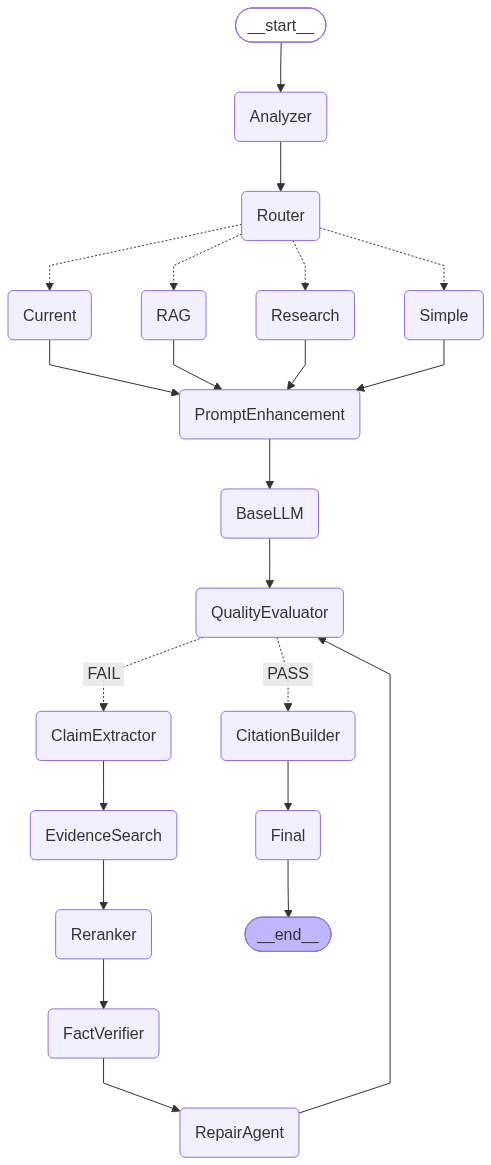

In [26]:
app = graph.compile()
app

In [27]:
result = app.invoke({
    "query":"What are the major approaches proposed in research papers for detecting and reducing hallucinations in large language models, and how do they differ?"
    # 
    # "query": "What are the major approaches proposed in research papers for detecting and reducing hallucinations in large language models, and how do they differ?"
    })

In [28]:
print("ROUTE:")
print(result.get("route"))

print("\nANSWER:")
print(result.get("generated_answer"))

print("\nEVALUATION:")
print(result.get("evaluation"))

ROUTE:
Research

ANSWER:
The major approaches proposed in research papers for detecting and reducing hallucinations in large language models include:

1. **Prompt tuning approaches**: These aim to reduce hallucinations by modifying the prompting strategies, such as Chain-of-Thought prompting (Wei et al., 2022) and Self-Consistency decoding (Wang et al., 2022), which focus on improving model behavior rather than altering the model itself.

2. **Data filtering**: This involves selecting high-quality, biased, or informative data to reduce the likelihood of hallucinations.

3. **Model editing**: This method focuses on modifying the model itself to address hallucinations, such as through fine-tuning or training with different data.

4. **Hierarchical semantic piece (HSP)**: This framework unifies existing methods by introducing a novel approach for detecting and mitigating hallucinations, combining both detection and mitigation strategies.

These approaches differ in their focus: prompt tun